In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [98]:
penguins = sns.load_dataset("penguins")

penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


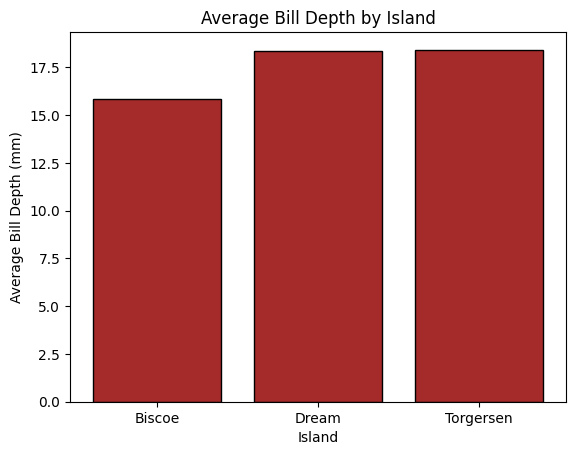

In [73]:
#Task 1: Bar Chart
penguins['island'].value_counts()

avg_bill_depth = penguins.groupby('island')['bill_depth_mm'].mean()

plt.bar(avg_bill_depth.index, avg_bill_depth.values, color='brown', edgecolor='black')
plt.xlabel('Island')
plt.ylabel('Average Bill Depth (mm)')
plt.title('Average Bill Depth by Island')
plt.show()

/tmp/ipykernel_3542/699334249.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:pink'` for the same effect.

  sns.countplot(data=penguins, x='species', hue='sex', color = 'pink')


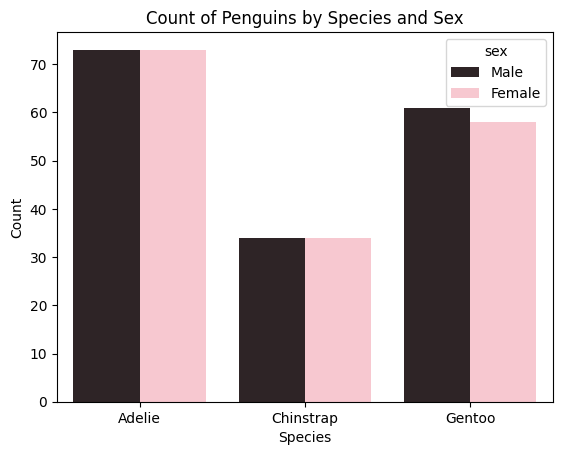

In [27]:
# Task 2: Count Plot

sns.countplot(data=penguins, x='species', hue='sex', color = 'pink')
plt.xlabel('Species')
plt.ylabel('Count')
plt.title('Count of Penguins by Species and Sex')
plt.show()

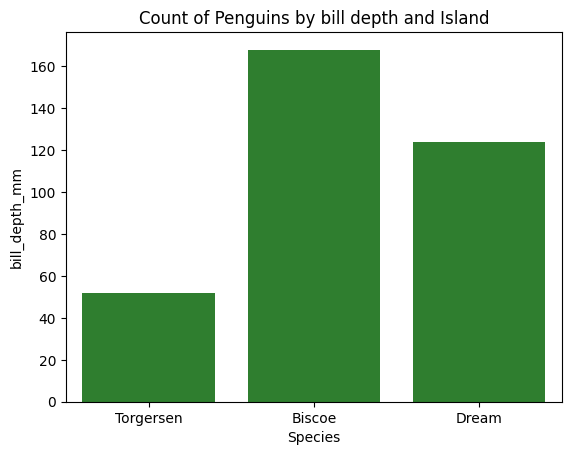

In [75]:
sns.countplot(data=penguins, x='island', color='forestgreen')
plt.xlabel('Islands')
plt.ylabel('bill_depth_mm')
plt.title('Count of Penguins by bill depth and Island')
plt.show()


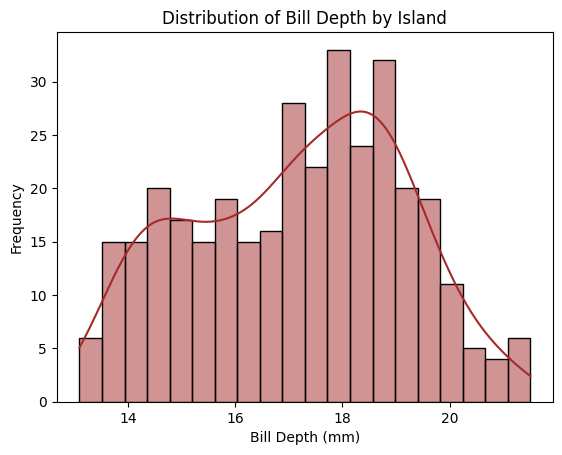

In [62]:
# Task 3: Histogram
sns.histplot(data=penguins, x='bill_depth_mm', bins=20, kde=True, color = 'brown')
plt.xlabel('Bill Depth (mm)')
plt.ylabel('Frequency')
plt.title('Distribution of Bill Depth by Island')
plt.show()

# Distributed almost normally

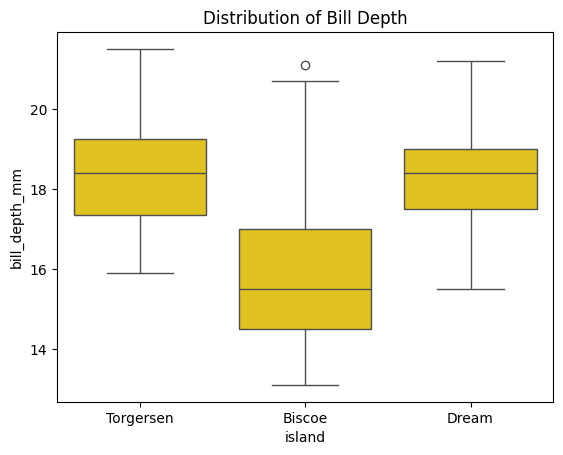

In [60]:
# Task 4:
sns.boxplot(data=penguins, x = 'island', y='bill_depth_mm', color='gold')
plt.title('Distribution of Bill Depth')
plt.show()

In [55]:
# Task 5: Outlier Detection using IQR
Q1 = penguins['bill_depth_mm'].quantile(0.25)
Q3 = penguins['bill_depth_mm'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = penguins[(penguins['bill_depth_mm'] < lower) | (penguins['bill_depth_mm'] > upper)]
print("Number Of Outliers in the numerical column: ", len(outliers))

Number Of Outliers in the numerical column:  0


In [56]:
# Task 6: Z Score:
penguins['zscore'] = stats.zscore(penguins['bill_depth_mm'])
outliers_z = penguins[abs(penguins['zscore']) > 3]
print("Number Of Outliers in the numerical column: ", len(outliers_z))

# IQR and Z-score flag same number of outliers

Number Of Outliers in the numerical column:  0


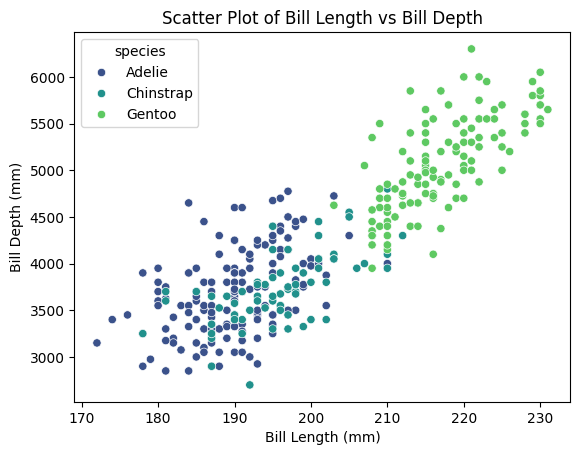

In [64]:
# Task 7: Scatter Plot
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g', hue='species', palette='viridis')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Bill Depth (mm)')
plt.title('Scatter Plot of Bill Length vs Bill Depth')
plt.show()

#Positive Relationship

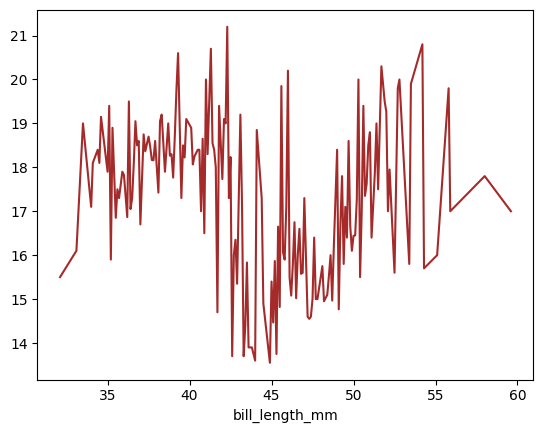

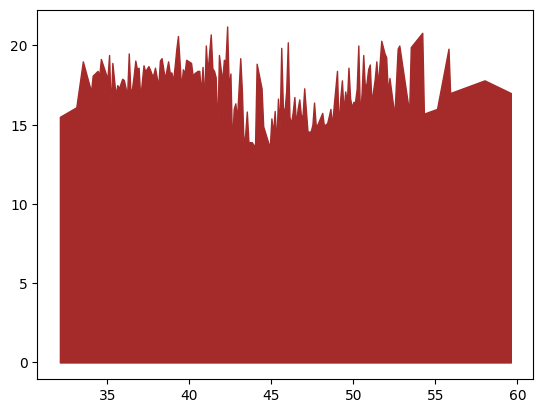

In [100]:
# Task 8:


data = penguins.groupby('bill_length_mm')['bill_depth_mm'].mean().sort_index()

sns.lineplot(x = data.index, y = data.values, color = 'brown')
plt.show()
plt.fill_between(data.index, data.values, color = 'brown')
plt.show()

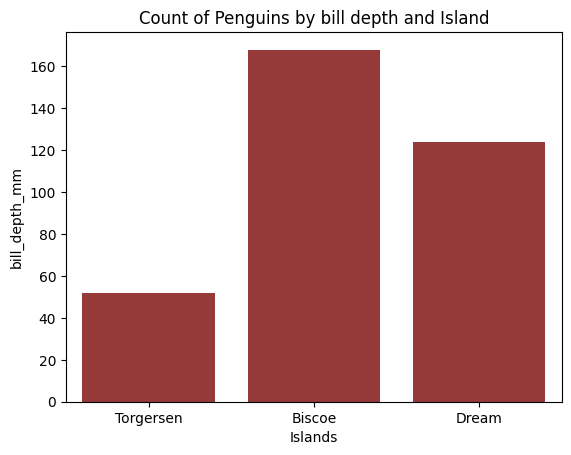

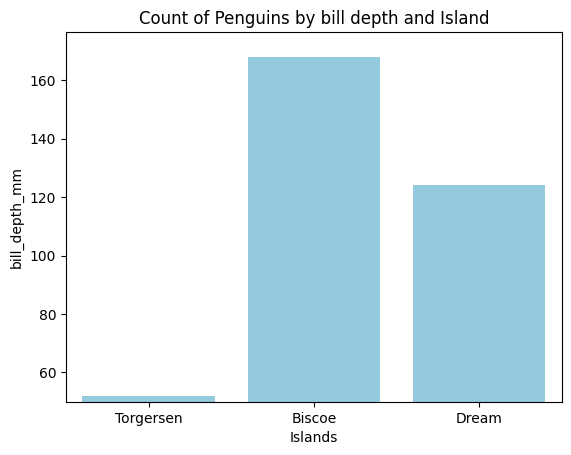

In [96]:
# Task 9:
sns.countplot(data=penguins, x='island', color='brown')
plt.xlabel('Islands')
plt.ylabel('bill_depth_mm')
plt.title('Count of Penguins by bill depth and Island')
plt.show()

sns.countplot(data=penguins, x='island', color='skyblue')
plt.xlabel('Islands')
plt.ylabel('bill_depth_mm')
plt.title('Count of Penguins by bill depth and Island')
plt.ylim(bottom=50)
plt.show()
